# Stage B: MultiRocket-eXtraTrees vs original MultiRocket + Ridge at 50,000 features

Both models run in the **same session**, on the same five UCR datasets (Coffee, ECG200, Adiac, ACSF1, Crop) and the same 30 predefined resamples (resample 0 = official split), with a similar number of features:

* **MultiRocket-eXtraTrees** (frozen from Stage A: pooling PPV, LSPV, MIPV, TP-PPV; Extra Trees with 300 trees), with K = 49 filters per kernel = 49,392 features.
* **Original MultiRocket + Ridge**, 50,000 features (about 49,728 actual).

**Run the cells in order, top to bottom, in a fresh runtime (Runtime > Change runtime type > High-RAM).** Cell 1 must be the first cell run after connecting.

## 1. Setup and settings (run first in a fresh runtime)

In [1]:
import os
SINGLE_THREAD = False      # False: all cores for BOTH models (same session, fair relative comparison)
if SINGLE_THREAD:
    os.environ["NUMBA_NUM_THREADS"] = "1"

K = 49                     # filters per kernel: 49 -> 49,392 features (K=5 -> 5,040)
N_ESTIMATORS = 300         # frozen
NUM_FEATURES_ORIG = 50000  # original MultiRocket default
N_RESAMPLES = 10           # lower (e.g. 10) if time is short

!pip -q install numba scikit-learn
!rm -rf _repo_tmp
!git clone -q https://github.com/ChangWeiTan/MultiRocket.git _repo_tmp
!cp -r _repo_tmp/multirocket _repo_tmp/data .
print("setup done | K =", K, "| expected features:", 84 * K * 12)

setup done | K = 49 | expected features: 49392


## 2. Frozen model code
Writes `multirocket/multirocket_extratrees.py` (the frozen model). Nothing to edit.

In [2]:
%%writefile multirocket/multirocket_extratrees.py
"""MultiRocket-eXtraTrees: MultiRocket with TP-PPV pooling (PPV, LSPV, MIPV, TP-PPV) and an Extra Trees classifier.

Main entry point: class MultiRocketXTrees (fit / predict). The feature function is transform_final.

Generated from the authors' multirocket.py (transform only); the original file is not modified.
Per series (original and first difference) the blocks are, in order:
    0 PPV | 1 LSPV | 2 MIPV | 3 TP-PPV early | 4 TP-PPV middle | 5 TP-PPV late
Call with n_features_per_kernel = 6.
"""
import numpy as np
from numba import njit, prange
from sklearn.ensemble import ExtraTreesClassifier

# Kernel/bias/dilation fitting is taken unchanged from the authors' implementation.
from multirocket.multirocket import fit as _fit_parameters


@njit(
    "float32[:,:](float64[:,:],float64[:,:],Tuple((int32[:],int32[:],float32[:])),Tuple((int32[:],int32[:],float32[:])),int32)",
    fastmath=True, parallel=True, cache=True)
def transform_final(X, X1, parameters, parameters1, n_features_per_kernel=4):
    num_examples, input_length = X.shape

    dilations, num_features_per_dilation, biases = parameters
    dilations1, num_features_per_dilation1, biases1 = parameters1

    # equivalent to:
    # >>> from itertools import combinations
    # >>> indices = np.array([_ for _ in combinations(np.arange(9), 3)], dtype = np.int32)
    indices = np.array((
        0, 1, 2, 0, 1, 3, 0, 1, 4, 0, 1, 5, 0, 1, 6, 0, 1, 7, 0, 1, 8,
        0, 2, 3, 0, 2, 4, 0, 2, 5, 0, 2, 6, 0, 2, 7, 0, 2, 8, 0, 3, 4,
        0, 3, 5, 0, 3, 6, 0, 3, 7, 0, 3, 8, 0, 4, 5, 0, 4, 6, 0, 4, 7,
        0, 4, 8, 0, 5, 6, 0, 5, 7, 0, 5, 8, 0, 6, 7, 0, 6, 8, 0, 7, 8,
        1, 2, 3, 1, 2, 4, 1, 2, 5, 1, 2, 6, 1, 2, 7, 1, 2, 8, 1, 3, 4,
        1, 3, 5, 1, 3, 6, 1, 3, 7, 1, 3, 8, 1, 4, 5, 1, 4, 6, 1, 4, 7,
        1, 4, 8, 1, 5, 6, 1, 5, 7, 1, 5, 8, 1, 6, 7, 1, 6, 8, 1, 7, 8,
        2, 3, 4, 2, 3, 5, 2, 3, 6, 2, 3, 7, 2, 3, 8, 2, 4, 5, 2, 4, 6,
        2, 4, 7, 2, 4, 8, 2, 5, 6, 2, 5, 7, 2, 5, 8, 2, 6, 7, 2, 6, 8,
        2, 7, 8, 3, 4, 5, 3, 4, 6, 3, 4, 7, 3, 4, 8, 3, 5, 6, 3, 5, 7,
        3, 5, 8, 3, 6, 7, 3, 6, 8, 3, 7, 8, 4, 5, 6, 4, 5, 7, 4, 5, 8,
        4, 6, 7, 4, 6, 8, 4, 7, 8, 5, 6, 7, 5, 6, 8, 5, 7, 8, 6, 7, 8
    ), dtype=np.int32).reshape(84, 3)

    num_kernels = len(indices)
    num_dilations = len(dilations)
    num_dilations1 = len(dilations1)

    num_features = num_kernels * np.sum(num_features_per_dilation)
    num_features1 = num_kernels * np.sum(num_features_per_dilation1)

    features = np.zeros((num_examples, (num_features + num_features1) * n_features_per_kernel), dtype=np.float32)
    n_features_per_transform = np.int64(features.shape[1] / 2)

    for example_index in prange(num_examples):

        _X = X[example_index]

        A = -_X  # A = alpha * X = -X
        G = _X + _X + _X  # G = gamma * X = 3X

        # Base series
        feature_index_start = 0

        for dilation_index in range(num_dilations):

            _padding0 = dilation_index % 2

            dilation = dilations[dilation_index]
            padding = ((9 - 1) * dilation) // 2

            num_features_this_dilation = num_features_per_dilation[dilation_index]

            C_alpha = np.zeros(input_length, dtype=np.float32)
            C_alpha[:] = A

            C_gamma = np.zeros((9, input_length), dtype=np.float32)
            C_gamma[9 // 2] = G

            start = dilation
            end = input_length - padding

            for gamma_index in range(9 // 2):
                C_alpha[-end:] = C_alpha[-end:] + A[:end]
                C_gamma[gamma_index, -end:] = G[:end]

                end += dilation

            for gamma_index in range(9 // 2 + 1, 9):
                C_alpha[:-start] = C_alpha[:-start] + A[start:]
                C_gamma[gamma_index, :-start] = G[start:]

                start += dilation

            for kernel_index in range(num_kernels):

                feature_index_end = feature_index_start + num_features_this_dilation

                _padding1 = (_padding0 + kernel_index) % 2

                index_0, index_1, index_2 = indices[kernel_index]

                C = C_alpha + \
                    C_gamma[index_0] + \
                    C_gamma[index_1] + \
                    C_gamma[index_2]

                if _padding1 == 0:
                    for feature_count in range(num_features_this_dilation):
                        feature_index = feature_index_start + feature_count
                        _bias = biases[feature_index]

                        ppv = 0
                        last_val = 0
                        max_stretch = 0.0
                        mean_index = 0
                        for j in range(C.shape[0]):
                            if C[j] > _bias:
                                ppv += 1
                                mean_index += j
                            elif C[j] < _bias:
                                stretch = j - last_val
                                if stretch > max_stretch:
                                    max_stretch = stretch
                                last_val = j
                        stretch = C.shape[0] - 1 - last_val
                        if stretch > max_stretch:
                            max_stretch = stretch

                        end = feature_index
                        features[example_index, end] = ppv / C.shape[0]
                        end = end + num_features
                        features[example_index, end] = max_stretch
                        end = end + num_features
                        features[example_index, end] = mean_index / ppv if ppv > 0 else -1
                        # Additional pooling: temporal-pyramid PPV (early / middle / late thirds)
                        values = C
                        n_response = values.shape[0]
                        cut_1 = n_response // 3
                        cut_2 = (2 * n_response) // 3
                        early_count = 0
                        middle_count = 0
                        late_count = 0
                        for jj in range(n_response):
                            if values[jj] > _bias:
                                if jj < cut_1:
                                    early_count += 1
                                elif jj < cut_2:
                                    middle_count += 1
                                else:
                                    late_count += 1
                        features[example_index, end + num_features] = early_count / max(cut_1, 1)
                        features[example_index, end + 2 * num_features] = middle_count / max(cut_2 - cut_1, 1)
                        features[example_index, end + 3 * num_features] = late_count / max(n_response - cut_2, 1)
                else:
                    _c = C[padding:-padding]

                    for feature_count in range(num_features_this_dilation):
                        feature_index = feature_index_start + feature_count
                        _bias = biases[feature_index]

                        ppv = 0
                        last_val = 0
                        max_stretch = 0.0
                        mean_index = 0
                        for j in range(_c.shape[0]):
                            if _c[j] > _bias:
                                ppv += 1
                                mean_index += j
                            elif _c[j] < _bias:
                                stretch = j - last_val
                                if stretch > max_stretch:
                                    max_stretch = stretch
                                last_val = j
                        stretch = _c.shape[0] - 1 - last_val
                        if stretch > max_stretch:
                            max_stretch = stretch

                        end = feature_index
                        features[example_index, end] = ppv / _c.shape[0]
                        end = end + num_features
                        features[example_index, end] = max_stretch
                        end = end + num_features
                        features[example_index, end] = mean_index / ppv if ppv > 0 else -1
                        # Additional pooling: temporal-pyramid PPV (early / middle / late thirds)
                        values = _c
                        n_response = values.shape[0]
                        cut_1 = n_response // 3
                        cut_2 = (2 * n_response) // 3
                        early_count = 0
                        middle_count = 0
                        late_count = 0
                        for jj in range(n_response):
                            if values[jj] > _bias:
                                if jj < cut_1:
                                    early_count += 1
                                elif jj < cut_2:
                                    middle_count += 1
                                else:
                                    late_count += 1
                        features[example_index, end + num_features] = early_count / max(cut_1, 1)
                        features[example_index, end + 2 * num_features] = middle_count / max(cut_2 - cut_1, 1)
                        features[example_index, end + 3 * num_features] = late_count / max(n_response - cut_2, 1)

                feature_index_start = feature_index_end

        # First order difference
        _X1 = X1[example_index]
        A1 = -_X1  # A = alpha * X = -X
        G1 = _X1 + _X1 + _X1  # G = gamma * X = 3X

        feature_index_start = 0

        for dilation_index in range(num_dilations1):

            _padding0 = dilation_index % 2

            dilation = dilations1[dilation_index]
            padding = ((9 - 1) * dilation) // 2

            num_features_this_dilation = num_features_per_dilation1[dilation_index]

            C_alpha = np.zeros(input_length - 1, dtype=np.float32)
            C_alpha[:] = A1

            C_gamma = np.zeros((9, input_length - 1), dtype=np.float32)
            C_gamma[9 // 2] = G1

            start = dilation
            end = input_length - padding

            for gamma_index in range(9 // 2):
                C_alpha[-end:] = C_alpha[-end:] + A1[:end]
                C_gamma[gamma_index, -end:] = G1[:end]

                end += dilation

            for gamma_index in range(9 // 2 + 1, 9):
                C_alpha[:-start] = C_alpha[:-start] + A1[start:]
                C_gamma[gamma_index, :-start] = G1[start:]

                start += dilation

            for kernel_index in range(num_kernels):

                feature_index_end = feature_index_start + num_features_this_dilation

                _padding1 = (_padding0 + kernel_index) % 2

                index_0, index_1, index_2 = indices[kernel_index]

                C = C_alpha + \
                    C_gamma[index_0] + \
                    C_gamma[index_1] + \
                    C_gamma[index_2]

                if _padding1 == 0:
                    for feature_count in range(num_features_this_dilation):
                        feature_index = feature_index_start + feature_count
                        _bias = biases1[feature_index]

                        ppv = 0
                        last_val = 0
                        max_stretch = 0.0
                        mean_index = 0
                        for j in range(C.shape[0]):
                            if C[j] > _bias:
                                ppv += 1
                                mean_index += j
                            elif C[j] < _bias:
                                stretch = j - last_val
                                if stretch > max_stretch:
                                    max_stretch = stretch
                                last_val = j
                        stretch = C.shape[0] - 1 - last_val
                        if stretch > max_stretch:
                            max_stretch = stretch

                        end = feature_index + n_features_per_transform
                        features[example_index, end] = ppv / C.shape[0]
                        end = end + num_features
                        features[example_index, end] = max_stretch
                        end = end + num_features
                        features[example_index, end] = mean_index / ppv if ppv > 0 else -1
                        # Additional pooling: temporal-pyramid PPV (early / middle / late thirds)
                        values = C
                        n_response = values.shape[0]
                        cut_1 = n_response // 3
                        cut_2 = (2 * n_response) // 3
                        early_count = 0
                        middle_count = 0
                        late_count = 0
                        for jj in range(n_response):
                            if values[jj] > _bias:
                                if jj < cut_1:
                                    early_count += 1
                                elif jj < cut_2:
                                    middle_count += 1
                                else:
                                    late_count += 1
                        features[example_index, end + num_features] = early_count / max(cut_1, 1)
                        features[example_index, end + 2 * num_features] = middle_count / max(cut_2 - cut_1, 1)
                        features[example_index, end + 3 * num_features] = late_count / max(n_response - cut_2, 1)
                else:
                    _c = C[padding:-padding]

                    for feature_count in range(num_features_this_dilation):
                        feature_index = feature_index_start + feature_count
                        _bias = biases1[feature_index]

                        ppv = 0
                        last_val = 0
                        max_stretch = 0.0
                        mean_index = 0
                        for j in range(_c.shape[0]):
                            if _c[j] > _bias:
                                ppv += 1
                                mean_index += j
                            elif _c[j] < _bias:
                                stretch = j - last_val
                                if stretch > max_stretch:
                                    max_stretch = stretch
                                last_val = j
                        stretch = _c.shape[0] - 1 - last_val
                        if stretch > max_stretch:
                            max_stretch = stretch

                        end = feature_index + n_features_per_transform
                        features[example_index, end] = ppv / _c.shape[0]
                        end = end + num_features
                        features[example_index, end] = max_stretch
                        end = end + num_features
                        features[example_index, end] = mean_index / ppv if ppv > 0 else -1
                        # Additional pooling: temporal-pyramid PPV (early / middle / late thirds)
                        values = _c
                        n_response = values.shape[0]
                        cut_1 = n_response // 3
                        cut_2 = (2 * n_response) // 3
                        early_count = 0
                        middle_count = 0
                        late_count = 0
                        for jj in range(n_response):
                            if values[jj] > _bias:
                                if jj < cut_1:
                                    early_count += 1
                                elif jj < cut_2:
                                    middle_count += 1
                                else:
                                    late_count += 1
                        features[example_index, end + num_features] = early_count / max(cut_1, 1)
                        features[example_index, end + 2 * num_features] = middle_count / max(cut_2 - cut_1, 1)
                        features[example_index, end + 3 * num_features] = late_count / max(n_response - cut_2, 1)

                feature_index_start = feature_index_end

    return features


@njit
def _set_numba_seed(seed):
    np.random.seed(seed)


class MultiRocketXTrees:
    """MultiRocket-eXtraTrees: MultiRocket features with TP-PPV pooling (PPV, LSPV, MIPV, TP-PPV) + Extra Trees.

    Usage
    -----
        model = MultiRocketXTrees(random_state=0)
        model.fit(X_train, y_train)      # X: array (n_series, series_length), univariate
        y_pred = model.predict(X_test)

    Parameters
    ----------
    filters_per_kernel : int, default 5
        K: number of bias values (thresholds) per kernel. The 84 kernels are fixed, so the number
        of feature columns is 84 * K * 2 * 6 (original + first-difference series, 6 pooling blocks),
        i.e. 5,040 for K=5.
    n_estimators : int, default 300
        Number of Extra Trees.
    random_state : int, default 0
        Seed for the random biases (Numba) and for Extra Trees.
    n_jobs : int, default -1
        Number of parallel jobs for Extra Trees.
    """

    N_BLOCKS = 6   # PPV, LSPV, MIPV, TP-PPV early, middle, late

    def __init__(self, filters_per_kernel=5, n_estimators=300, random_state=0, n_jobs=-1):
        self.filters_per_kernel = filters_per_kernel
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.n_jobs = n_jobs

    @staticmethod
    def _check(X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2:
            raise ValueError("X must be 2-D: (n_series, series_length); univariate series only.")
        if X.shape[1] < 10:
            raise ValueError("Series must have at least 10 time points.")
        if not np.isfinite(X).all():
            raise ValueError("X contains NaN or infinite values.")
        return np.ascontiguousarray(X)

    def transform(self, X):
        """Return the feature matrix (n_series, 84 * K * 2 * 6)."""
        X = self._check(X)
        D = np.ascontiguousarray(np.diff(X, axis=1))
        F = transform_final(X, D, self.parameters_, self.parameters_diff_, self.N_BLOCKS)
        return np.nan_to_num(F, nan=0.0, posinf=0.0, neginf=0.0)

    def fit(self, X, y):
        X = self._check(X)
        D = np.ascontiguousarray(np.diff(X, axis=1))
        num_features = 84 * int(self.filters_per_kernel)

        _set_numba_seed(int(self.random_state))
        self.parameters_ = _fit_parameters(X, num_features=num_features)
        self.parameters_diff_ = _fit_parameters(D, num_features=num_features)

        features = self.transform(X)
        self.n_features_ = features.shape[1]
        self.classifier_ = ExtraTreesClassifier(
            n_estimators=self.n_estimators, max_features="sqrt", min_samples_leaf=1,
            n_jobs=self.n_jobs, random_state=self.random_state)
        self.classifier_.fit(features, y)
        self.classes_ = self.classifier_.classes_
        return self

    def _batches(self, X, batch_size):
        X = self._check(X)
        for start in range(0, X.shape[0], batch_size):
            yield X[start:start + batch_size]

    def predict(self, X, batch_size=2000):
        """Predict class labels. Features are generated in batches to keep memory use low
        (important for large K, e.g. K=49 gives ~49,000 columns)."""
        return np.concatenate([self.classifier_.predict(self.transform(b)) for b in self._batches(X, batch_size)])

    def predict_proba(self, X, batch_size=2000):
        return np.vstack([self.classifier_.predict_proba(self.transform(b)) for b in self._batches(X, batch_size)])

    def score(self, X, y, batch_size=2000):
        return float(np.mean(self.predict(X, batch_size=batch_size) == np.asarray(y)))


# Backward-compatible alias
MultiRocketFinal = MultiRocketXTrees


Writing multirocket/multirocket_extratrees.py


## 3. Download the five datasets

In [3]:
from pathlib import Path
import urllib.request, zipfile
import pandas as pd

root = Path("data/UCRArchive_2018")
DATASETS = ["Coffee", "ECG200", "Adiac", "ACSF1", "Crop"]

for name in DATASETS:
    folder = root / name
    folder.mkdir(parents=True, exist_ok=True)
    archive = Path(f"/tmp/{name}.zip")
    if not archive.exists():
        urllib.request.urlretrieve(
            f"https://www.timeseriesclassification.com/aeon-toolkit/{name}.zip", archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(folder)
    for split in ["TRAIN", "TEST"]:
        src = folder / f"{name}_{split}.txt"
        dst = folder / f"{name}_{split}.tsv"
        if src.exists():
            pd.read_csv(src, sep=r"\s+", header=None).to_csv(
                dst, sep="\t", header=False, index=False)
    ok = all((folder / f"{name}_{s}.tsv").exists() for s in ["TRAIN", "TEST"])
    print(name, "READY" if ok else "MISSING")

Coffee READY
ECG200 READY
Adiac READY
ACSF1 READY
Crop READY


## 4. Quick check (about 1 minute): feature count and Numba warm-up
The number of features must equal 84 x K x 12. The warm-up compiles the Numba code so that compilation time is not counted in the results.

In [4]:
import numpy as np
from multirocket.multirocket_extratrees import MultiRocketXTrees

def load_tsv(path):
    arr = np.loadtxt(path, delimiter="\t")
    return arr[:, 1:].astype(np.float64), arr[:, 0]

Xc, yc = load_tsv("data/UCRArchive_2018/Coffee/Coffee_TRAIN.tsv")
m = MultiRocketXTrees(filters_per_kernel=K, n_estimators=10, random_state=0,
                      n_jobs=1 if SINGLE_THREAD else -1).fit(Xc, yc)
print("features:", m.n_features_, "| expected:", 84 * K * 12)
assert m.n_features_ == 84 * K * 12

features: 49392 | expected: 49392


## 5. MultiRocket-eXtraTrees: 5 datasets x 30 resamples
Results are appended to `stageB_final_K{K}.csv` after every resample. If the session stops, run the cell again: finished resamples are skipped.

In [5]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

N_JOBS = 1 if SINGLE_THREAD else -1
DATA_PATH = Path("data/UCRArchive_2018")
INDEX_PATH = Path("data/indices109")
OUT_CSV = Path(f"stageB_final_K{K}.csv")

def get_split(name, it, X_all, y_all, n_train0):
    if it == 0:
        return np.arange(n_train0), np.arange(n_train0, len(y_all))
    idx_file = INDEX_PATH / f"{name}_INDICES_TRAIN.txt"
    tr = np.loadtxt(idx_file, skiprows=it, max_rows=1).astype(np.int32)
    te = np.setdiff1d(np.arange(len(y_all)), tr)
    return tr, te

def load_dataset(name):
    folder = DATA_PATH / name
    X_tr0, y_tr0 = load_tsv(folder / f"{name}_TRAIN.tsv")
    X_te0, y_te0 = load_tsv(folder / f"{name}_TEST.tsv")
    X_all = np.vstack((X_tr0, X_te0))
    y_all = LabelEncoder().fit_transform(np.concatenate((y_tr0, y_te0)))
    return X_all, y_all, len(y_tr0)

rows = pd.read_csv(OUT_CSV).to_dict("records") if OUT_CSV.exists() else []
done = {(r["Dataset"], int(r["Resample"])) for r in rows}
print("already done:", len(done), "| threads:", "1" if SINGLE_THREAD else "all")

for name in DATASETS:
    X_all, y_all, n_train0 = load_dataset(name)
    for it in range(N_RESAMPLES):
        if (name, it) in done:
            continue
        tr, te = get_split(name, it, X_all, y_all, n_train0)
        Xtr = np.ascontiguousarray(X_all[tr]); ytr = y_all[tr]
        Xte = np.ascontiguousarray(X_all[te]); yte = y_all[te]

        t0 = time.perf_counter()
        model = MultiRocketXTrees(filters_per_kernel=K, n_estimators=N_ESTIMATORS,
                                  random_state=it, n_jobs=N_JOBS).fit(Xtr, ytr)
        fit_s = time.perf_counter() - t0

        t0 = time.perf_counter()
        pred = model.predict(Xte)
        pred_s = time.perf_counter() - t0

        rows.append({"Dataset": name, "Resample": it,
                     "Accuracy": 100 * accuracy_score(yte, pred),
                     "Fit_s": fit_s, "Predict_s": pred_s, "Total_s": fit_s + pred_s})
        pd.DataFrame(rows).to_csv(OUT_CSV, index=False)
        print(f"{name:7s} resample {it:2d}  acc {rows[-1]['Accuracy']:6.2f}  total {fit_s + pred_s:6.1f} s")

print("finished")

already done: 0 | threads: all
Coffee  resample  0  acc 100.00  total    0.8 s
Coffee  resample  1  acc 100.00  total    0.7 s
Coffee  resample  2  acc 100.00  total    0.7 s
Coffee  resample  3  acc 100.00  total    0.7 s
Coffee  resample  4  acc 100.00  total    0.7 s
Coffee  resample  5  acc 100.00  total    0.6 s
Coffee  resample  6  acc 100.00  total    0.6 s
Coffee  resample  7  acc 100.00  total    0.6 s
Coffee  resample  8  acc 100.00  total    0.6 s
Coffee  resample  9  acc  96.43  total    0.7 s
ECG200  resample  0  acc  88.00  total    0.8 s
ECG200  resample  1  acc  77.00  total    0.7 s
ECG200  resample  2  acc  89.00  total    0.7 s
ECG200  resample  3  acc  88.00  total    0.7 s
ECG200  resample  4  acc  91.00  total    0.7 s
ECG200  resample  5  acc  86.00  total    0.7 s
ECG200  resample  6  acc  84.00  total    0.7 s
ECG200  resample  7  acc  88.00  total    0.7 s
ECG200  resample  8  acc  89.00  total    0.7 s
ECG200  resample  9  acc  88.00  total    0.7 s
Adiac   r

## 6. Original MultiRocket + Ridge, 50,000 features (same session)

Run after section 5, in the same runtime. Same datasets, same resamples, same threads setting. Results go to `stageB_original_50k.csv` (finished resamples are skipped when you run the cell again).

In [6]:
# Same patch as in the reproduction notebook: remove the argument that newer scikit-learn no longer accepts.
p = Path("multirocket/multirocket.py")
src = p.read_text()
print("normalize=False before:", src.count("normalize=False"))
p.write_text(src.replace("normalize=False", ""))

import importlib, multirocket.multirocket as mr_module
importlib.reload(mr_module)
from multirocket.multirocket import MultiRocket

OUT_CSV_ORIG = Path("stageB_original_50k.csv")
rows_o = pd.read_csv(OUT_CSV_ORIG).to_dict("records") if OUT_CSV_ORIG.exists() else []
done_o = {(r["Dataset"], int(r["Resample"])) for r in rows_o}
print("already done:", len(done_o))

for name in DATASETS:
    X_all, y_all, n_train0 = load_dataset(name)
    for it in range(N_RESAMPLES):
        if (name, it) in done_o:
            continue
        tr, te = get_split(name, it, X_all, y_all, n_train0)
        Xtr = X_all[tr]; ytr = y_all[tr]
        Xte = X_all[te]; yte = y_all[te]

        model = MultiRocket(num_features=NUM_FEATURES_ORIG, classifier="ridge", verbose=0)

        t0 = time.perf_counter()
        model.fit(Xtr, ytr, predict_on_train=False)
        fit_s = time.perf_counter() - t0

        t0 = time.perf_counter()
        pred = model.predict(Xte)
        pred_s = time.perf_counter() - t0

        rows_o.append({"Dataset": name, "Resample": it,
                       "Accuracy": 100 * accuracy_score(yte, pred),
                       "Fit_s": fit_s, "Predict_s": pred_s, "Total_s": fit_s + pred_s})
        pd.DataFrame(rows_o).to_csv(OUT_CSV_ORIG, index=False)
        print(f"{name:7s} resample {it:2d}  acc {rows_o[-1]['Accuracy']:6.2f}  total {fit_s + pred_s:6.1f} s")

print("finished")

normalize=False before: 1
already done: 0
Coffee  resample  0  acc 100.00  total    0.3 s
Coffee  resample  1  acc 100.00  total    0.3 s
Coffee  resample  2  acc 100.00  total    0.3 s
Coffee  resample  3  acc 100.00  total    0.3 s
Coffee  resample  4  acc 100.00  total    0.3 s
Coffee  resample  5  acc 100.00  total    0.3 s
Coffee  resample  6  acc 100.00  total    0.3 s
Coffee  resample  7  acc 100.00  total    0.3 s
Coffee  resample  8  acc 100.00  total    0.3 s
Coffee  resample  9  acc 100.00  total    0.3 s
ECG200  resample  0  acc  92.00  total    0.6 s
ECG200  resample  1  acc  89.00  total    0.6 s
ECG200  resample  2  acc  88.00  total    0.5 s
ECG200  resample  3  acc  89.00  total    0.5 s
ECG200  resample  4  acc  91.00  total    0.5 s
ECG200  resample  5  acc  92.00  total    0.5 s
ECG200  resample  6  acc  91.00  total    0.6 s
ECG200  resample  7  acc  91.00  total    0.6 s
ECG200  resample  8  acc  94.00  total    0.6 s
ECG200  resample  9  acc  88.00  total    0.5 

## 7. Control: original MultiRocket + logistic regression, 50,000 features (same session)

The authors' pipeline also offers logistic regression as the classifier (the paper suggests it for larger datasets because it trains faster). Same settings as in section 6: same datasets, same resamples, same threads setting. Results go to `stageB_original_logistic_50k.csv` (finished resamples are skipped when you run the cell again).

**Only Adiac, ACSF1 and Crop are run.** Coffee and ECG200 have two classes, and the authors' logistic regression code fails on binary targets (`ValueError: Target size must be the same as input size`). Running it on them would need a change to the original code, so they are left out of this control.

In [7]:
from multirocket.multirocket import MultiRocket

OUT_CSV_LOG = Path("stageB_original_logistic_50k.csv")
rows_l = pd.read_csv(OUT_CSV_LOG).to_dict("records") if OUT_CSV_LOG.exists() else []
done_l = {(r["Dataset"], int(r["Resample"])) for r in rows_l}

for name in ["Adiac", "ACSF1", "Crop"]:      # Coffee and ECG200 are binary: the authors' code fails on them
    X_all, y_all, n_train0 = load_dataset(name)
    for it in range(N_RESAMPLES):
        if (name, it) in done_l:
            continue
        tr, te = get_split(name, it, X_all, y_all, n_train0)
        model = MultiRocket(num_features=NUM_FEATURES_ORIG, classifier="logistic", verbose=0)

        t0 = time.perf_counter()
        model.fit(X_all[tr], y_all[tr], predict_on_train=False)
        fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = model.predict(X_all[te])
        pred_s = time.perf_counter() - t0

        rows_l.append({"Dataset": name, "Resample": it,
                       "Accuracy": 100 * accuracy_score(y_all[te], pred),
                       "Fit_s": fit_s, "Predict_s": pred_s, "Total_s": fit_s + pred_s})
        pd.DataFrame(rows_l).to_csv(OUT_CSV_LOG, index=False)
        print(f"{name:7s} resample {it:2d}  acc {rows_l[-1]['Accuracy']:6.2f}  total {fit_s + pred_s:6.1f} s")
print("finished")

epoch: 0: 2it [00:00,  9.33it/s]                       
epoch: 1: 2it [00:00, 37.31it/s]               
epoch: 2: 2it [00:00, 40.67it/s]               
epoch: 3: 2it [00:00, 40.19it/s]               
epoch: 4: 2it [00:00, 39.16it/s]               
epoch: 5: 2it [00:00, 39.67it/s]               
epoch: 6: 2it [00:00, 38.89it/s]               
epoch: 7: 2it [00:00, 39.08it/s]               
epoch: 8: 2it [00:00, 39.07it/s]               
epoch: 9: 2it [00:00, 40.42it/s]               
epoch: 10: 2it [00:00, 36.46it/s]               
epoch: 11: 2it [00:00, 41.96it/s]               
epoch: 12: 2it [00:00, 40.40it/s]               
epoch: 13: 2it [00:00, 41.82it/s]               
epoch: 14: 2it [00:00, 43.24it/s]               
epoch: 15: 2it [00:00, 43.00it/s]               
epoch: 16: 2it [00:00, 39.57it/s]               
epoch: 17: 2it [00:00, 40.69it/s]               
epoch: 18: 2it [00:00, 40.81it/s]               
epoch: 19: 2it [00:00, 38.54it/s]               
epoch: 20: 2it [00:00,


<Stopped at Epoch 79>
Adiac   resample  0  acc  79.03  total   10.9 s


epoch: 0: 2it [00:00, 34.72it/s]               
epoch: 1: 2it [00:00, 37.47it/s]               
epoch: 2: 2it [00:00, 35.66it/s]               
epoch: 3: 2it [00:00, 38.17it/s]               
epoch: 4: 2it [00:00, 37.37it/s]               
epoch: 5: 2it [00:00, 38.58it/s]               
epoch: 6: 2it [00:00, 36.16it/s]               
epoch: 7: 2it [00:00, 40.13it/s]               
epoch: 8: 2it [00:00, 40.78it/s]               
epoch: 9: 2it [00:00, 41.86it/s]               
epoch: 10: 2it [00:00, 36.73it/s]               
epoch: 11: 2it [00:00, 41.83it/s]               
epoch: 12: 2it [00:00, 39.31it/s]               
epoch: 13: 2it [00:00, 41.03it/s]               
epoch: 14: 2it [00:00, 40.49it/s]               
epoch: 15: 2it [00:00, 40.74it/s]               
epoch: 16: 2it [00:00, 30.69it/s]               
epoch: 17: 2it [00:00, 41.15it/s]               
epoch: 18: 2it [00:00, 35.19it/s]               
epoch: 19: 2it [00:00, 39.84it/s]               
epoch: 20: 2it [00:00, 35.08it


<Stopped at Epoch 49>
Adiac   resample  1  acc  75.70  total    3.8 s


epoch: 0: 2it [00:00, 38.77it/s]               
epoch: 1: 2it [00:00, 39.82it/s]               
epoch: 2: 2it [00:00, 36.12it/s]               
epoch: 3: 2it [00:00, 40.41it/s]               
epoch: 4: 2it [00:00, 40.70it/s]               
epoch: 5: 2it [00:00, 36.71it/s]               
epoch: 6: 2it [00:00, 31.03it/s]               
epoch: 7: 2it [00:00, 39.53it/s]               
epoch: 8: 2it [00:00, 35.41it/s]               
epoch: 9: 2it [00:00, 32.21it/s]               
epoch: 10: 2it [00:00, 30.04it/s]               
epoch: 11: 2it [00:00, 40.19it/s]               
epoch: 12: 2it [00:00, 40.65it/s]               
epoch: 13: 2it [00:00, 41.21it/s]               
epoch: 14: 2it [00:00, 39.20it/s]               
epoch: 15: 2it [00:00, 34.59it/s]               
epoch: 16: 2it [00:00, 40.74it/s]               
epoch: 17: 2it [00:00, 41.90it/s]               
epoch: 18: 2it [00:00, 40.76it/s]               
epoch: 19: 2it [00:00, 41.40it/s]               
epoch: 20: 2it [00:00, 23.80it


<Stopped at Epoch 32>
Adiac   resample  2  acc  76.47  total    2.8 s


... (50 outputs left out)

epoch: 73:  75%|███████▌  | 21/28 [00:00<00:00, 31.84it/s]



<Stopped at Epoch 74>
Crop    resample  8  acc  75.36  total   79.6 s


epoch: 43:  75%|███████▌  | 21/28 [00:00<00:00, 32.16it/s]



<Stopped at Epoch 44>
Crop    resample  9  acc  74.87  total   53.1 s
finished


## 8. Comparison table

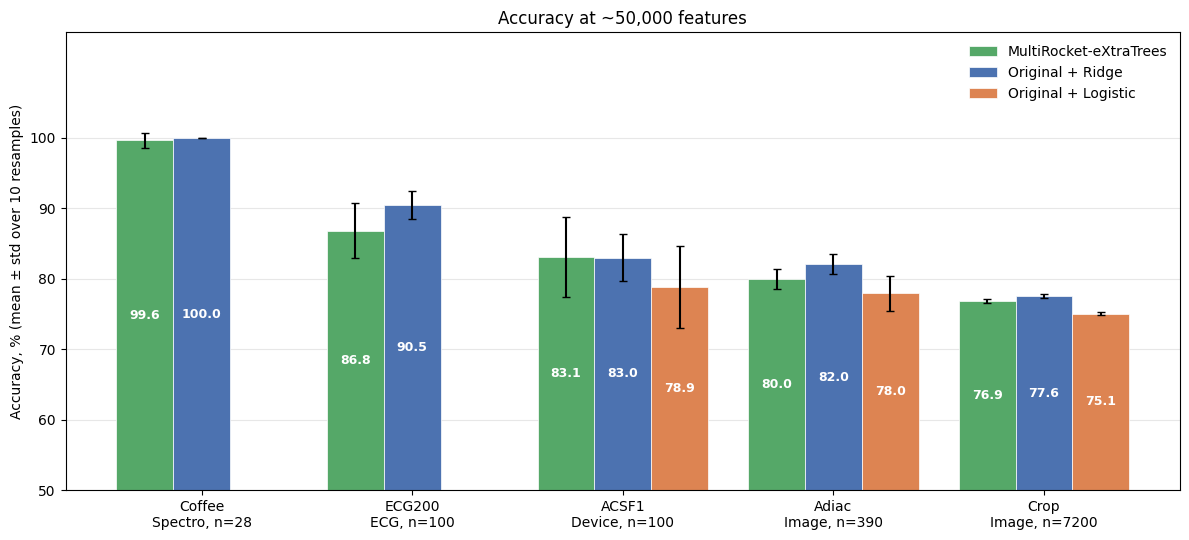

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

K = 49
files = {                                   # порядок = порядок стовпців
    "MultiRocket-eXtraTrees": f"stageB_final_K{K}.csv",
    "Original + Ridge":       "stageB_original_50k.csv",
    "Original + Logistic":    "stageB_original_logistic_50k.csv",
}
colors = {
    "MultiRocket-eXtraTrees": "#55A868",
    "Original + Ridge":       "#4C72B0",
    "Original + Logistic":    "#DD8452",
}

meta = {
    "Coffee": ("Spectro", 28),
    "ECG200": ("ECG",     100),
    "ACSF1":  ("Device",  100),
    "Adiac":  ("Image",   390),
    "Crop":   ("Image",   7200),
}
order = ["Coffee", "ECG200", "ACSF1", "Adiac", "Crop"]

def pick(df, names):
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n in low:
            return low[n]
    raise KeyError(f"Немає колонки з {names}. Є: {list(df.columns)}")

stats = {}
for name, path in files.items():
    df = pd.read_csv(path)
    dcol = pick(df, ["dataset", "data", "name"])
    acol = pick(df, ["acc", "accuracy", "test_acc"])
    acc = df[acol].astype(float)
    if acc.max() <= 1.0:
        acc = acc * 100
    stats[name] = df.assign(_acc=acc).groupby(dcol)["_acc"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(12, 5.5))
n = len(files)
width = 0.27
x = np.arange(len(order))

for i, (name, g) in enumerate(stats.items()):
    means = np.array([g["mean"].get(d, np.nan) for d in order])
    stds  = np.array([g["std"].get(d, np.nan)  for d in order])
    pos = x + (i - (n - 1) / 2) * width
    ax.bar(pos, means, width, yerr=stds, capsize=3, label=name,
           color=colors[name], edgecolor="white", linewidth=0.5)
    for p, m in zip(pos, means):
        if not np.isnan(m):
            ax.text(p, (50 + m) / 2, f"{m:.1f}", ha="center", va="center",
                    fontsize=9, color="white", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n{meta[d][0]}, n={meta[d][1]}" for d in order])
ax.set_ylabel("Accuracy, % (mean ± std over 10 resamples)")
ax.set_ylim(50, 115)
ax.set_yticks(range(50, 101, 10))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=False)
ax.set_title("Accuracy at ~50,000 features")
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=300)
plt.show()

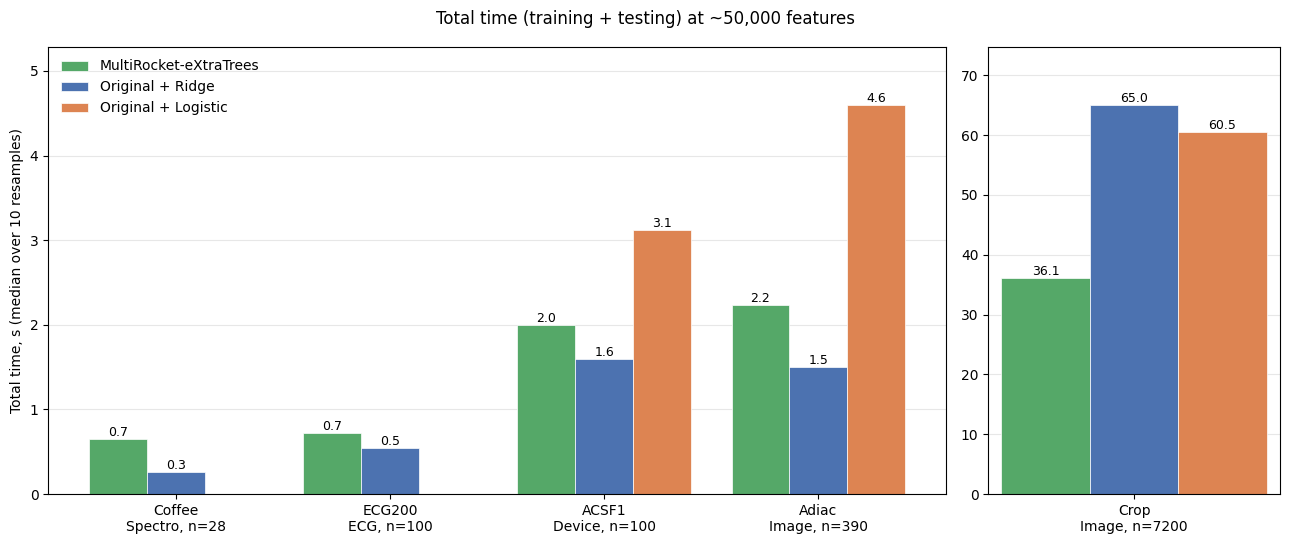

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

K = 49
files = {
    "MultiRocket-eXtraTrees": f"stageB_final_K{K}.csv",
    "Original + Ridge":       "stageB_original_50k.csv",
    "Original + Logistic":    "stageB_original_logistic_50k.csv",
}
colors = {
    "MultiRocket-eXtraTrees": "#55A868",
    "Original + Ridge":       "#4C72B0",
    "Original + Logistic":    "#DD8452",
}
meta = {
    "Coffee": ("Spectro", 28),
    "ECG200": ("ECG",     100),
    "ACSF1":  ("Device",  100),
    "Adiac":  ("Image",   390),
    "Crop":   ("Image",   7200),
}
small = ["Coffee", "ECG200", "ACSF1", "Adiac"]
large = ["Crop"]

def find(df, names):
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n in low:
            return low[n]
    return None

med = {}
for name, path in files.items():
    df = pd.read_csv(path)
    dcol = find(df, ["dataset", "data", "name"])
    tcol = find(df, ["total_s", "total", "total_time", "total_time_s", "time_total"])
    if tcol is not None:
        t = df[tcol].astype(float)
    else:
        tr = find(df, ["train_s", "train", "train_time", "training"])
        te = find(df, ["test_s", "test", "test_time", "testing"])
        if tr is None or te is None:
            raise KeyError(f"Немає колонок часу. Є: {list(df.columns)}")
        t = df[tr].astype(float) + df[te].astype(float)
    med[name] = df.assign(_t=t).groupby(dcol)["_t"].median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=False,
                               gridspec_kw={"width_ratios": [4, 1.3]})
n = len(files)
width = 0.27

def draw(ax, names):
    x = np.arange(len(names))
    top = 0
    for i, (name, g) in enumerate(med.items()):
        vals = np.array([g.get(d, np.nan) for d in names])
        pos = x + (i - (n - 1) / 2) * width
        ax.bar(pos, vals, width, label=name, color=colors[name],
               edgecolor="white", linewidth=0.5)
        for p, v in zip(pos, vals):
            if not np.isnan(v):
                ax.text(p, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
        top = max(top, np.nanmax(vals))
    ax.set_ylim(0, top * 1.15)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{d}\n{meta[d][0]}, n={meta[d][1]}" for d in names])
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

draw(ax1, small)
draw(ax2, large)
ax1.set_ylabel("Total time, s (median over 10 resamples)")
ax1.legend(loc="upper left", frameon=False)
fig.suptitle("Total time (training + testing) at ~50,000 features")
plt.tight_layout()
plt.savefig("time_comparison.png", dpi=300)
plt.show()

In [ ]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

NAME = "Crop"
N_RUNS = 3                                   # можна потім збільшити до 10
TRAIN_SIZES = [500, 1000, 2500, 5000, 7200]
FEATURES = {1000: 1, 5000: 5, 10000: 10, 25000: 25, 50000: 49}   # номінал -> K для нашої моделі
OUT = Path("crop_grid.csv")

methods = ["MultiRocket-eXtraTrees", "Original + Ridge", "Original + Logistic"]

rows = pd.read_csv(OUT).to_dict("records") if OUT.exists() else []
done = {(r["Method"], int(r["TrainSize"]), int(r["NumFeatures"]), int(r["Resample"])) for r in rows}
print("already done:", len(done))

X_all, y_all, n_train0 = load_dataset(NAME)

def run(method, n, nf, K, it):
    tr, te = get_split(NAME, it, X_all, y_all, n_train0)
    if n < len(tr):
        tr, _ = train_test_split(tr, train_size=n, stratify=y_all[tr], random_state=it)
    Xtr = np.ascontiguousarray(X_all[tr]); ytr = y_all[tr]
    Xte = np.ascontiguousarray(X_all[te]); yte = y_all[te]

    if method == "MultiRocket-eXtraTrees":
        model = MultiRocketXTrees(filters_per_kernel=K, n_estimators=N_ESTIMATORS,
                                  random_state=it, n_jobs=N_JOBS)
        t0 = time.perf_counter(); model.fit(Xtr, ytr); fit_s = time.perf_counter() - t0
    else:
        clf = "ridge" if method == "Original + Ridge" else "logistic"
        model = MultiRocket(num_features=nf, classifier=clf, verbose=0)
        t0 = time.perf_counter(); model.fit(Xtr, ytr, predict_on_train=False); fit_s = time.perf_counter() - t0

    t0 = time.perf_counter(); pred = model.predict(Xte); pred_s = time.perf_counter() - t0
    return 100 * accuracy_score(yte, pred), fit_s, pred_s

for it in range(N_RUNS):                      # зовнішній цикл = вибірка, тож після кожної повної сітки можна зупинитись
    for n in TRAIN_SIZES:
        for nf, K in FEATURES.items():
            for method in methods:
                if (method, n, nf, it) in done:
                    continue
                acc, fit_s, pred_s = run(method, n, nf, K, it)
                rows.append({"Method": method, "TrainSize": n, "NumFeatures": nf, "Resample": it,
                             "Accuracy": acc, "Fit_s": fit_s, "Predict_s": pred_s,
                             "Total_s": fit_s + pred_s})
                pd.DataFrame(rows).to_csv(OUT, index=False)
                print(f"run {it}  n={n:5d}  nf={nf:6d}  {method:24s} acc {acc:6.2f}  fit {fit_s:6.1f} s")

print("finished")

## 9. Crop: training-set size × number of features

We trained the three classifiers on Crop subsamples of 500–7,200 training series, with 1,000–50,000 features, and compared them on the full test set. Accuracy is the mean and training time the median over the resamples. Tables and plots below are built from `crop_grid.csv`.

resamples: 3 | runs: 225

Accuracy, % (mean)


Method                 MultiRocket-eXtraTrees  Original + Logistic  \
TrainSize NumFeatures                                                
500       1000                           61.9                 55.5   
          5000                           64.9                 62.8   
          10000                          64.6                 62.5   
          25000                          64.8                 62.9   
          50000                          64.8                 63.0   
1000      1000                           66.1                 60.2   
          5000                           68.1                 67.2   
          10000                          68.3                 67.7   
          25000                          68.3                 67.9   
          50000                          68.4                 67.9   
2500      1000                           69.8                 55.6   
          5000                           71.9                 62.9   
          10000                          72.0                 62.5   
          25000                          72.4                 61.9   
          50000                          72.3                 62.1   
5000      1000                           73.0                 66.7   
          5000                           75.0                 72.2   
          10000                          75.1                 72.5   
          25000                          75.4                 72.5   
          50000                          75.5                 72.5   
7200      1000                           74.5                 68.7   
          5000                           76.6                 74.4   
          10000                          76.7                 74.4   
          25000                          76.8                 74.7   
          50000                          76.7                 74.9   

Method                 Original + Ridge  
TrainSize NumFeatures                    
500       1000                     55.8  
          5000                     63.6  
          10000                    64.2  
          25000                    64.2  
          50000                    64.4  
1000      1000                     60.0  
          5000                     67.6  
          10000                    68.1  
          25000                    68.7  
          50000                    69.1  
2500      1000                     63.9  
          5000                     71.9  
          10000                    72.3  
          25000                    73.0  
          50000                    73.3  
5000      1000                     67.2  
          5000                     74.6  
          10000                    75.2  
          25000                    76.0  
          50000                    76.2  
7200      1000                     68.3  
          5000                     75.9  
          10000                    76.2  
          25000                    77.1  
          50000                    77.5


Training time, s (median)


Method                 MultiRocket-eXtraTrees  Original + Logistic  \
TrainSize NumFeatures                                                
500       1000                            0.4                  2.1   
          5000                            0.5                  2.8   
          10000                           0.7                  3.7   
          25000                           1.1                  4.7   
          50000                           1.7                  9.4   
1000      1000                            0.6                  3.1   
          5000                            1.0                  5.1   
          10000                           1.4                  6.8   
          25000                           2.2                 13.4   
          50000                           3.2                 23.8   
2500      1000                            0.9                  4.8   
          5000                            2.1                  6.3   
          10000                           3.3                  6.7   
          25000                           5.6                  8.1   
          50000                           8.0                 17.0   
5000      1000                            1.7                  9.2   
          5000                            4.4                 15.7   
          10000                           6.7                 12.7   
          25000                          11.5                 20.7   
          50000                          16.6                 23.6   
7200      1000                            2.6                 13.1   
          5000                            6.3                 19.8   
          10000                           9.8                 20.5   
          25000                          16.7                 18.9   
          50000                          24.8                 39.0   

Method                 Original + Ridge  
TrainSize NumFeatures                    
500       1000                      0.3  
          5000                      0.3  
          10000                     0.3  
          25000                     0.6  
          50000                     0.9  
1000      1000                      0.3  
          5000                      0.6  
          10000                     0.7  
          25000                     1.2  
          50000                     1.9  
2500      1000                      0.5  
          5000                      2.2  
          10000                     2.8  
          25000                     4.4  
          50000                     6.7  
5000      1000                      0.7  
          5000                     27.7  
          10000                    12.1  
          25000                    17.2  
          50000                    23.8  
7200      1000                      1.0  
          5000                     39.9  
          10000                    31.1  
          25000                    38.5  
          50000                    50.4


Most accurate method per cell


NumFeatures,1000,5000,10000,25000,50000
TrainSize,,,,,
500,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees
1000,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,Original + Ridge,Original + Ridge
2500,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,Original + Ridge,Original + Ridge,Original + Ridge
5000,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,Original + Ridge,Original + Ridge,Original + Ridge
7200,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,MultiRocket-eXtraTrees,Original + Ridge,Original + Ridge


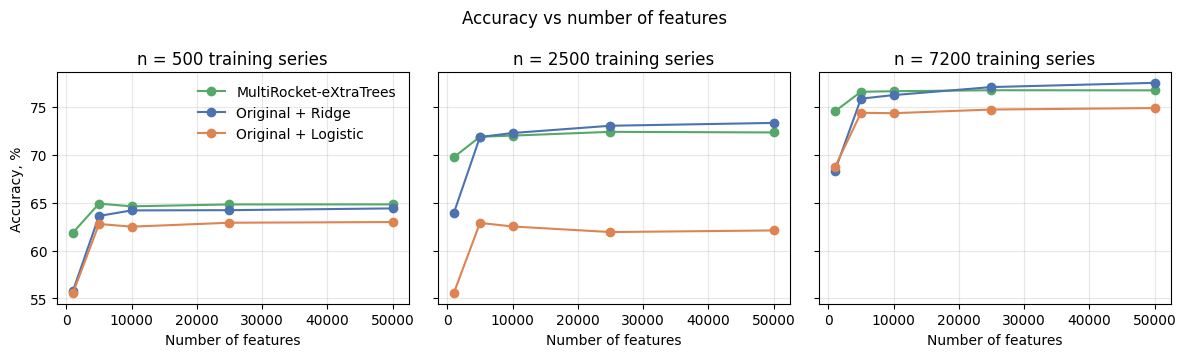

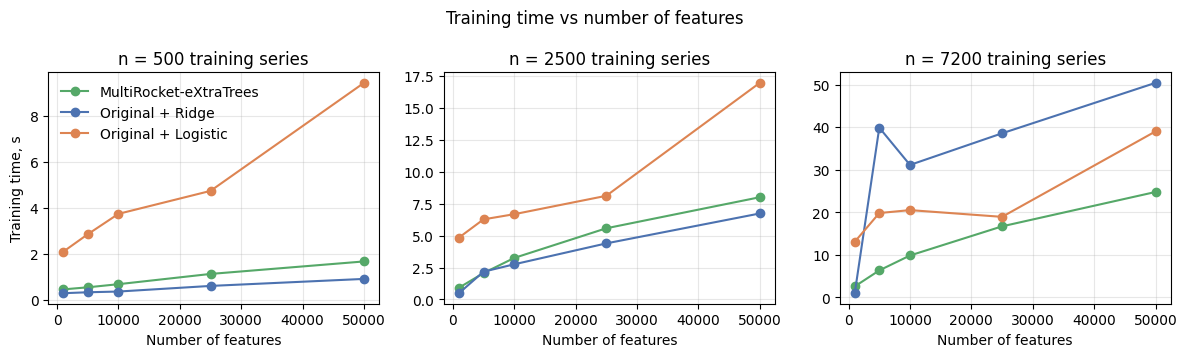

In [16]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

g = pd.read_csv("crop_grid.csv")
print("resamples:", g.Resample.nunique(), "| runs:", len(g))

key = ["TrainSize", "NumFeatures", "Method"]
acc = g.groupby(key).Accuracy.mean().unstack()          # точність, %
fit = g.groupby(key).Fit_s.median().unstack()           # час тренування, с

print("\nAccuracy, % (mean)");          display(acc.round(1))
print("\nTraining time, s (median)");   display(fit.round(1))
print("\nMost accurate method per cell")
display(acc.idxmax(axis=1).unstack("NumFeatures"))

colors = {"MultiRocket-eXtraTrees": "#55A868", "Original + Ridge": "#4C72B0", "Original + Logistic": "#DD8452"}
sizes = [500, 2500, 7200]

for table, ylabel, title in [(acc, "Accuracy, %", "Accuracy vs number of features"),
                             (fit, "Training time, s", "Training time vs number of features")]:
    fig, axes = plt.subplots(1, len(sizes), figsize=(12, 3.6), sharey=(table is acc))
    for ax, n in zip(axes, sizes):
        sub = table.loc[n]
        for m in colors:
            ax.plot(sub.index, sub[m], marker="o", label=m, color=colors[m])
        ax.set_title(f"n = {n} training series")
        ax.set_xlabel("Number of features")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel)
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()